Video utilizado para importar base de datos:
https://www.youtube.com/watch?v=SrT6QkQUH4Q

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
mnist = tf.keras.datasets.mnist
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

print("Base de datos 'X_train_full' con 60000 imágenes de 28x28 pixeles")
print(f"- Tipo: {X_train_full.dtype} - Dimensión: {X_train_full.shape}")

print(f"- {type(X_train_full)}")

Base de datos 'X_train_full' con 60000 imágenes de 28x28 pixeles
- Tipo: uint8 - Dimensión: (60000, 28, 28)
- <class 'numpy.ndarray'>


In [4]:
print(f"Cantidad de 5s ya etiquetados dentro de la Base de datos 'X_train_full': {np.count_nonzero(y_train_full == 5)}")

Cantidad de 5s ya etiquetados dentro de la Base de datos 'X_train_full': 5421


In [5]:
X_train_editada = [] # Lista que almacenará las imágenes que representan un 5

for k in range(len(y_train_full)):
    if y_train_full[k] == 5:
        X_train_editada.append(X_train_full[k] / 255)

# Verificador:
print(f"Media de pixeles de la imagen 43: {np.mean(X_train_editada[43])}")
print(f"Desviación estándar de pixeles de la imagen 43: {np.std(X_train_editada[43])}")

Media de pixeles de la imagen 43: 0.08330332132853141
Desviación estándar de pixeles de la imagen 43: 0.24055851962078895


<Axes: >

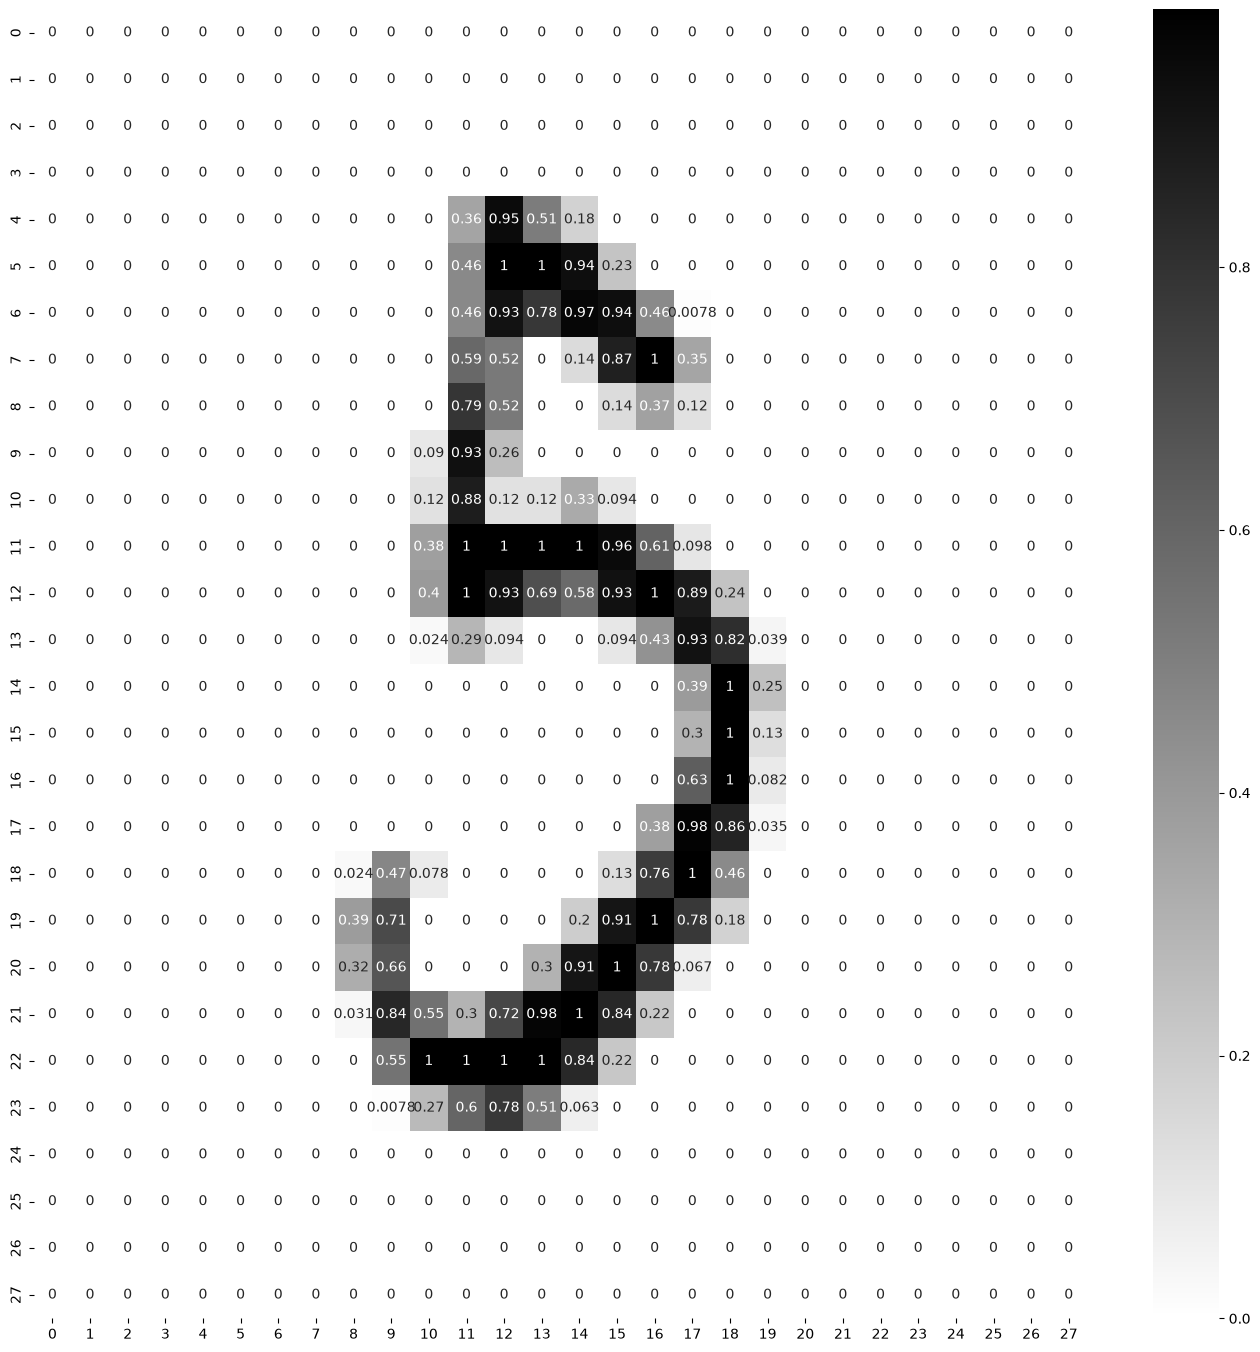

In [265]:
plt.figure(figsize=(17,17))
sns.heatmap(X_train_editada[43], annot=True, cmap='binary')

In [173]:
X_flattened = []
for imagen in X_train_editada:
    imagen_flattened = imagen.flatten()
    X_flattened.append(imagen_flattened)

X_flattened = np.matrix(X_flattened)
print(f"Dimensión de X_flattened: {X_flattened.shape}")
# Se pasó de 6000 imágenes almacenadas como matrices a 6000 imágenes almacenadas como vectores de 784 elementos

Dimensión de X_flattened: (5421, 784)


In [191]:
medias = np.mean(X_flattened, axis=0)
varianzas = np.var(X_flattened, axis=0)
var_total = np.sum(varianzas)
# print(varianzas)
print("Varianza total aportada por las 784 características:", var_total)

Varianza total aportada por las 784 características: 47.581013525619454


In [190]:
X = X_flattened - medias

In [184]:
n = X.shape[0]  # Número de imágenes o tamaño muestral
r = X.shape[1]  # Número de caracteristicas de cada imagen o individuo

matriz_covarianza = np.matrix(np.zeros((r, r)))
for imagen in X:
    matriz_covarianza += (np.transpose(imagen) @ imagen) / n

print(f"Dimensión de la matriz de covarianza: {matriz_covarianza.shape}")

Dimensión de la matriz de covarianza: (784, 784)


In [185]:
# Valores propios y Vectores propios de la matriz de covarianza
eigenvalues, eigenvectors = np.linalg.eigh(matriz_covarianza)

print(f"Cantidad de valores propios: {len(eigenvalues)}")
# print(f"Valores propios: {eigenvalues}")
# print(f"Vectores propios: {eigenvectors}")


Cantidad de valores propios: 784


In [ ]:
eigenvalues_sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[eigenvalues_sorted_indices]
varianza_aportada = eigenvalues_sorted / var_total
eigenvectors_sorted = eigenvectors[:, eigenvalues_sorted_indices]

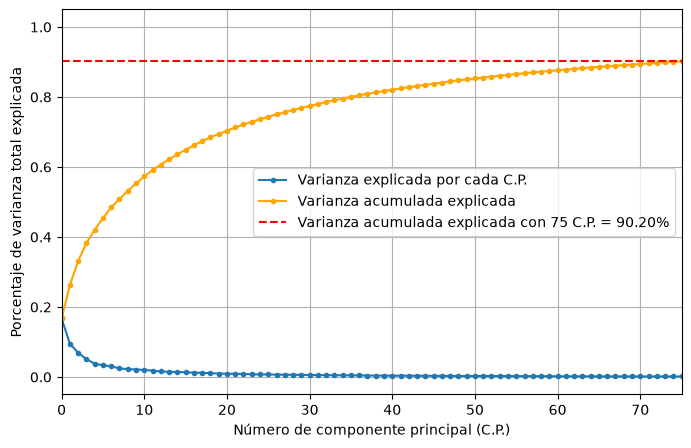

In [269]:
num_CP = 75 # Número de componentes principales (C.P.) escogidas
var_acum_explicada = np.cumsum(varianza_aportada)[num_CP] # % de varianza acumulada explicada por 'num_CP' C.P.

plt.figure(figsize=(8, 5))
plt.plot(varianza_aportada, marker='o', label = 'Varianza explicada por cada C.P.', ms=3)
plt.plot(np.cumsum(varianza_aportada), marker='o', color='orange', label='Varianza acumulada explicada', ms=3)
plt.axhline(var_acum_explicada, color='red',linestyle='--', label=f'Varianza acumulada explicada con {num_CP} C.P. = {var_acum_explicada * 100:.2f}%')
plt.xlabel("Número de componente principal (C.P.)")
plt.ylabel("Porcentaje de varianza total explicada")
plt.xlim(0, num_CP)
plt.legend()
plt.grid()